# **Project Overview**

##### **This project presents a complete customer segmentation workflow using Unsupervised Machine Learning techniques.**

The objective is to identify groups of customers with similar purchasing behavior, demographic characteristics, and marketing responses to support data-driven business decisions.

### **1- Machine Learning Pipeline**

| #  | Project Stage                       | Description                                                                  |
| -- | ----------------------------------- | ---------------------------------------------------------------------------- |
| 1  | **Data Understanding**              | Inspecting the dataset structure, features, data types, and basic statistics |
| 2  | **Data Cleaning**                   | Handling missing values, duplicates, and inconsistent data                   |
| 3  | **Feature Engineering**             | Creating and transforming features to improve clustering performance         |
| 4  | **Exploratory Data Analysis (EDA)** | Analyzing data distributions, relationships, and customer patterns           |
| 5  | **Feature Scaling & Selection**     | Standardizing numerical features to ensure balanced distance calculations    |
| 6  | **Clustering Models**               | Applying and comparing multiple unsupervised learning algorithms             |
| 7  | **Models Comparison & Selection**   | Evaluating clustering quality using multiple performance metrics             |
| 8  | **PCA Visualization**               | Reducing dimensionality to 2D/3D for visualizing customer clusters           |
| 9  | **Cluster Profiling**               | Analyzing the characteristics and behavior of each customer segment          |
| 10 | **Business Insights**               | Translating clustering results into actionable business recommendations      |

### **2- Clustering Models**

Five different clustering algorithms are implemented and compared:

| # | Model                                       | Main Purpose                                                                                 |
| - | ------------------------------------------- | -------------------------------------------------------------------------------------------- |
| 1 | **K-Means Clustering**                      | Partitioning customers into a predefined number of compact clusters                          |
| 2 | **Hierarchical / Agglomerative Clustering** | Building a hierarchy of customer groups based on similarity                                  |
| 3 | **DBSCAN**                                  | Identifying density-based clusters and detecting outliers                                    |
| 4 | **Gaussian Mixture Model (GMM)**            | Assigning customers to probabilistic clusters with flexible cluster shapes                   |
| 5 | **Mean Shift**                              | Discovering natural clusters based on data density without specifying the number of clusters |

### **3- Model Comparison**

The five clustering models are compared using multiple evaluation metrics to determine the most suitable algorithm for customer segmentation.

The comparison considers:

* **Silhouette Score**
* **Davies-Bouldin Index**
* **Calinski-Harabasz Index**
* **Number of Clusters**
* **Cluster Distribution**
* **Business Interpretability**

### **4- Cluster Profiling, Business Insights & Recommendations**

After selecting the best-performing clustering model, each customer segment is analyzed based on its key characteristics, including:

* **Customer behavior**
* **Purchasing patterns**
* **Demographic characteristics**
* **Marketing responses**
* **Spending patterns**

The final customer segments are translated into actionable business insights to support:


In [223]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

### **=> Data understanding & Initial exploration**
---

In [224]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


| Column | Description |
| --- | --- |
| **Year_Birth** | Customer's birth year (used to derive Age) |
| **Education** | Customer's education level |
| **Marital_Status** | Customer's marital status |
| **Income** | Customer's yearly household income |
| **Kidhome** | Number of children in the household |
| **Teenhome** | Number of teenagers in the household |
| **Dt_Customer** | Date the customer enrolled with the company (used to derive Tenure) |
| **Recency** | Number of days since the customer's last purchase |
| **MntWines** | Amount spent on wine in the last 2 years |
| **NumWebPurchases** | Number of purchases made through the company's website |

In [225]:
df.shape

(2240, 29)

In [226]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [227]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [228]:
df.describe(include="object").T

,count,unique,top,freq
Education,2240,5,Graduation,1127
Marital_Status,2240,8,Married,864
Dt_Customer,2240,663,31-08-2012,12


In [229]:
df.dtypes

ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

In [230]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

display(
    missing_values[
        missing_values["Missing Values"] > 0
    ].sort_values(
        by="Missing Values",
        ascending=False
    )
)

,Missing Values,Percentage (%)
Income,24,1.07


In [231]:
duplicates = df.duplicated().sum()
print(f"Duplicate Rows: {duplicates}")

Duplicate Rows: 0


### **=> Data Cleaning**
---

In [232]:
df = df.drop(columns=['ID', 'Z_CostContact', 'Z_Revenue']) # Constant Features
df["Income"] = df["Income"].fillna(df["Income"].median())

In [233]:
print(df.shape)
df = df.drop_duplicates()
print(df.shape) 

(2240, 26)
(2058, 26)


In [234]:
print(df['Marital_Status'].value_counts())

df['Marital_Status'] = df['Marital_Status'].replace({
    'Alone': 'Single', 'Absurd': 'Single', 'YOLO': 'Single',
    'Together': 'Partner', 'Married': 'Partner', 'Widow': 'Single'
})

Marital_Status
Married     795
Together    521
Single      448
Divorced    216
Widow        71
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


In [235]:
print(df['Education'].value_counts())

df['Education'] = df['Education'].replace({
    'Basic': 'Undergraduate', '2n Cycle': 'Postgraduate',
    'Master': 'Postgraduate', 'Graduation': 'Graduate', 'PhD': 'Postgraduate'
})

Education
Graduation    1030
PhD            450
Master         341
2n Cycle       188
Basic           49
Name: count, dtype: int64


In [236]:
print(df['Marital_Status'].value_counts(), end = "\n\n")
print(df['Education'].value_counts())

Marital_Status
Partner     1316
Single       526
Divorced     216
Name: count, dtype: int64

Education
Graduate         1030
Postgraduate      979
Undergraduate      49
Name: count, dtype: int64


In [237]:
df["Dt_Customer"] = pd.to_datetime(
    df["Dt_Customer"],
    format="%d-%m-%Y"
)

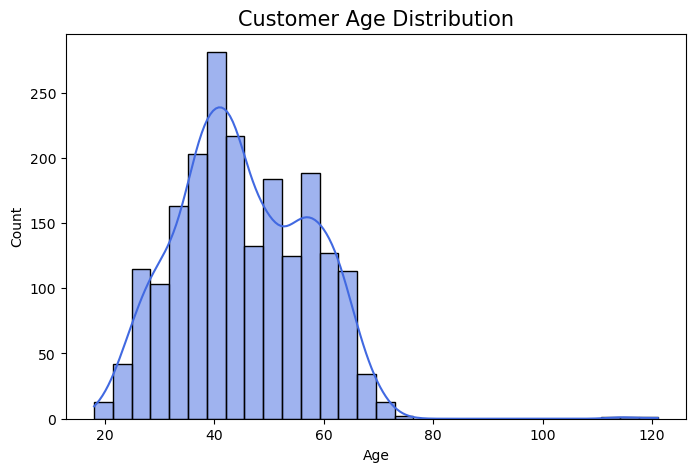

count    2058.000000
mean       45.212828
std        11.973898
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max       121.000000
Name: Age, dtype: float64


In [238]:
df["Age"] = df["Dt_Customer"].max().year - df["Year_Birth"]

plt.figure(figsize=(8,5))

sns.histplot(
    df["Age"],
    bins=30,
    kde=True,
    color="royalblue"
)

plt.title("Customer Age Distribution", fontsize=15)
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

print(df["Age"].describe())

In [239]:
df = df[(df["Age"] >= 18) & (df["Age"] <= 100)]
df["Age"].describe()

count    2055.000000
mean       45.108516
std        11.666261
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max        74.000000
Name: Age, dtype: float64

### **=> Feature Engineering**
---

In [240]:
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

df["Total_Purchases"] = df[["NumWebPurchases", "NumCatalogPurchases",
                            "NumStorePurchases"]].sum(axis=1)

df["Total_Accepted_Cmp"] = df[["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
                               "AcceptedCmp4", "AcceptedCmp5"]].sum(axis=1)

df["Total_Spending"] = df[["MntWines", "MntFruits", "MntMeatProducts",
                           "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1)

df["Customer_Tenure"] = (df["Dt_Customer"].max() - df["Dt_Customer"]).dt.days

In [241]:
df["Family_Size"] = df["Total_Children"] + df["Marital_Status"].map({
    "Single": 1, "Divorced": 1, "Partner": 2
})

In [242]:
display(df[["Total_Children", "Family_Size"]].describe())

,Total_Children,Family_Size
count,2055.000000,2055.000000
mean,0.955231,2.595134
std,0.748865,0.906847
min,0.000000,1.000000
25%,0.000000,2.000000
50%,1.000000,3.000000
75%,1.000000,3.000000
max,3.000000,5.000000


In [243]:
display(df["Total_Accepted_Cmp"].describe())


count    2055.000000
mean        0.300243
std         0.678559
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         4.000000
Name: Total_Accepted_Cmp, dtype: float64

In [244]:
print("\nSummary Statistics:\n")
display(
    df[
        ["Total_Spending", "Total_Purchases"]].describe().round(2)
)


Summary Statistics:



,Total_Spending,Total_Purchases
count,2055.00,2055.00
mean,606.18,12.54
std,602.39,7.19
min,5.00,0.00
25%,69.00,6.00
50%,397.00,12.00
75%,1046.00,18.00
max,2525.00,32.00


In [245]:
cols_to_drop = [
    "Year_Birth", "Dt_Customer",
    "Kidhome", "Teenhome",
    "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5",
]
df = df.drop(columns=cols_to_drop)

In [246]:
df.shape

(2055, 24)

In [247]:
df.head()

,Education,Marital_Status,Income,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,NumWebVisitsMonth,Complain,Response,Age,Total_Children,Total_Purchases,Total_Accepted_Cmp,Total_Spending,Customer_Tenure,Family_Size
0,Graduate,Single,58138.0,58,635,88,546,172,88,88,...,7,0,1,57,0,22,0,1617,663,1
1,Graduate,Single,46344.0,38,11,1,6,2,1,6,...,5,0,0,60,2,4,0,27,113,3
2,Graduate,Partner,71613.0,26,426,49,127,111,21,42,...,4,0,0,49,0,20,0,776,312,2
3,Graduate,Partner,26646.0,26,11,4,20,10,3,5,...,6,0,0,30,1,6,0,53,139,3
4,Postgraduate,Partner,58293.0,94,173,43,118,46,27,15,...,5,0,0,33,1,14,0,422,161,3


### **=> EDA & Data Visualization**
---

In [248]:
print(df["Response"].value_counts(normalize=True).mul(100).round(2))

Response
0    84.77
1    15.23
Name: proportion, dtype: float64


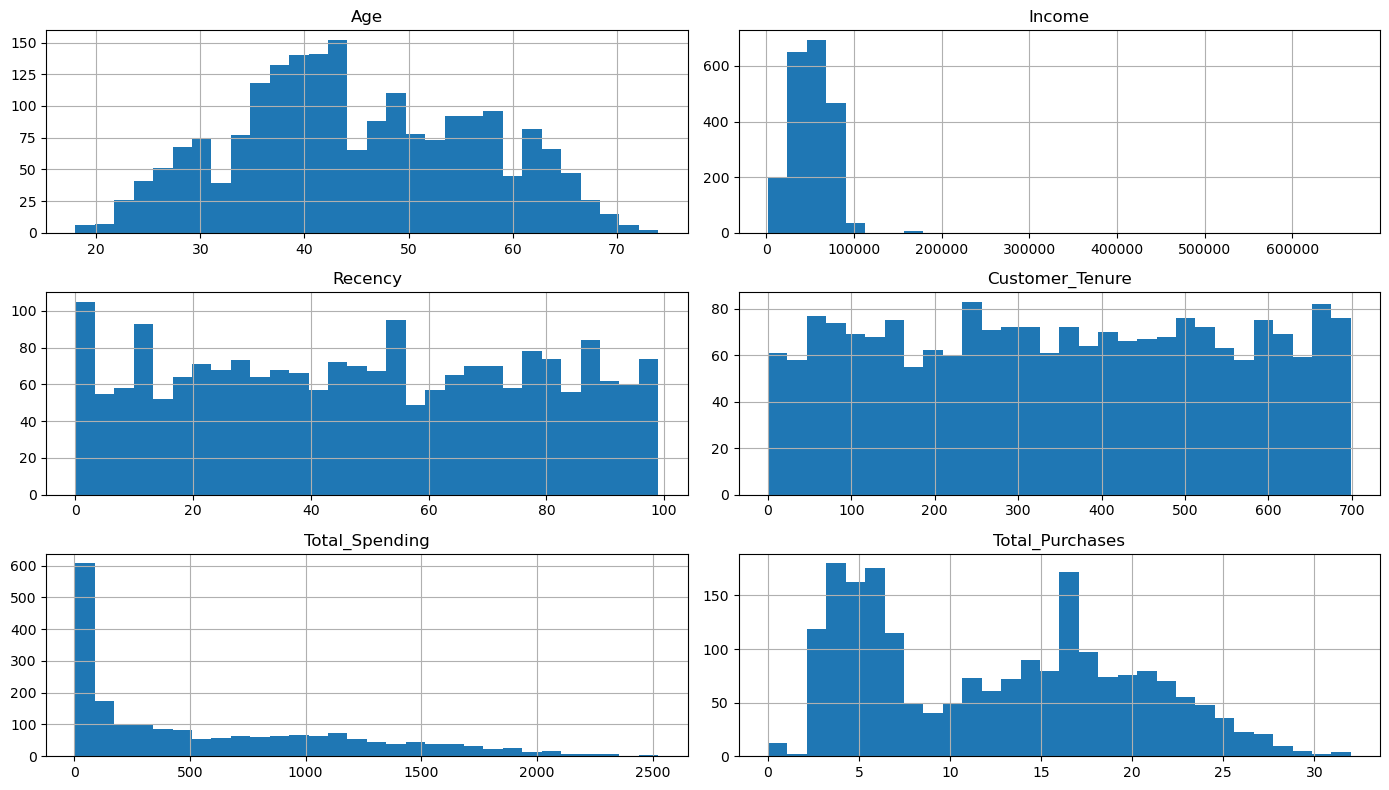

In [249]:
num_cols = ["Age", "Income", "Recency", "Customer_Tenure",
            "Total_Spending", "Total_Purchases"]

df[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

In [250]:
print(df[df["Income"] > 120000][["Income", "Total_Spending"]])

        Income  Total_Spending
164   157243.0            1608
617   162397.0             107
655   153924.0               6
687   160803.0            1717
1300  157733.0              59
1653  157146.0            1730
2132  156924.0               8
2233  666666.0              62


In [251]:
df = df[df["Income"] < 120000]

In [252]:
df["Total_Spending_log"] = np.log1p(df["Total_Spending"])

In [253]:
df.shape

(2047, 25)

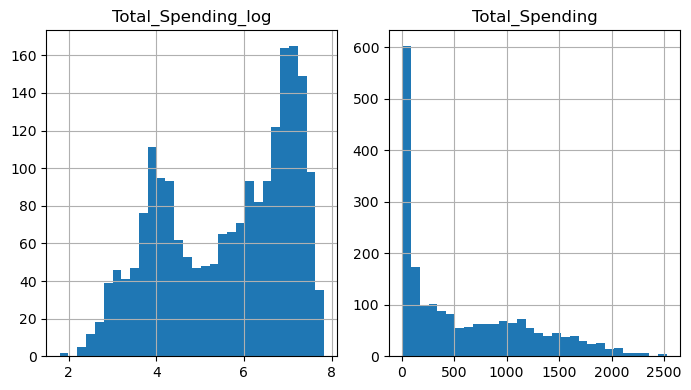

In [254]:
num_cols = ["Total_Spending_log",
            "Total_Spending"]

df[num_cols].hist(bins=30, figsize=(7, 4))
plt.tight_layout()
plt.show()

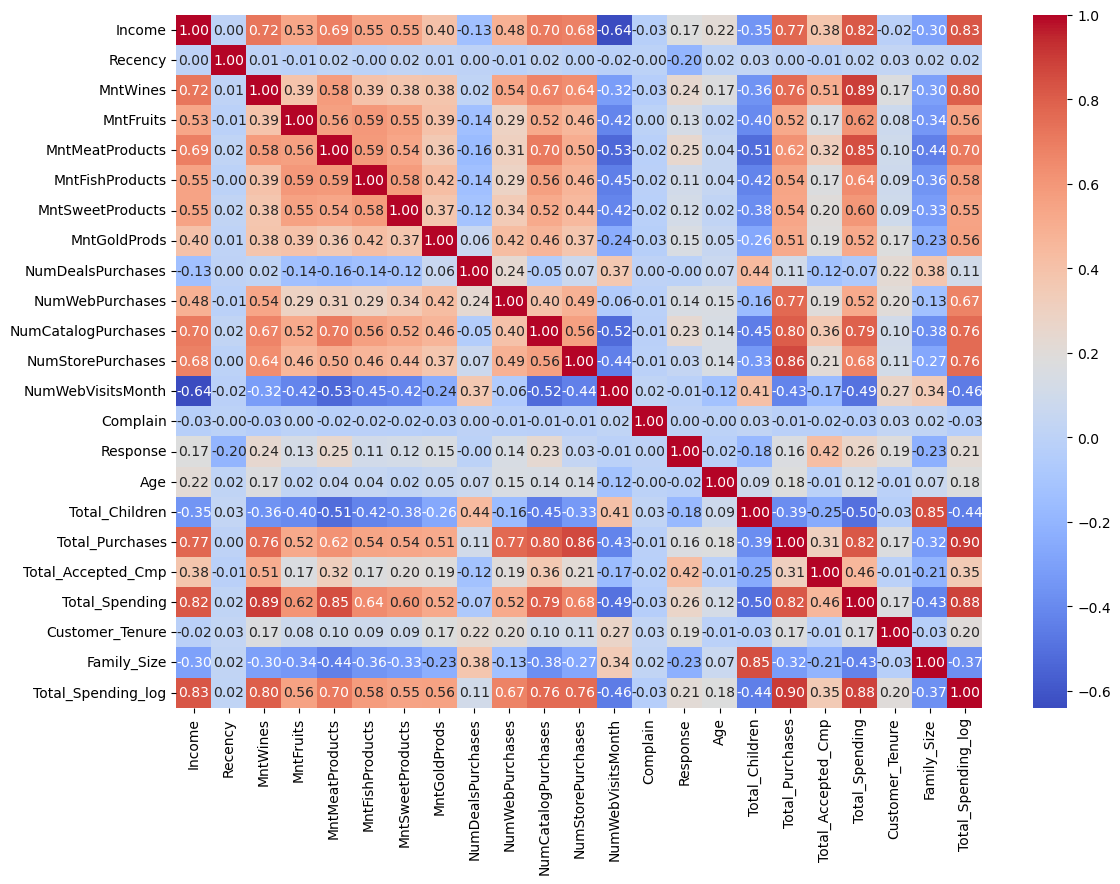

In [255]:
plt.figure(figsize=(13, 9))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

Education_Encoded     1.000000
Income                0.115685
Total_Spending_log    0.070300
Total_Purchases       0.067301
NumWebVisitsMonth    -0.039108
Name: Education_Encoded, dtype: float64


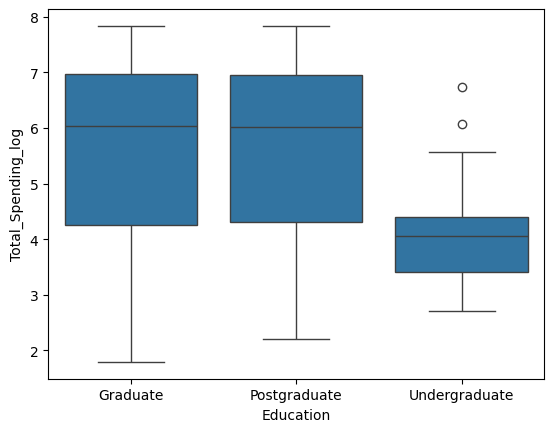

In [256]:
edu_map = {"Undergraduate": 0, "Graduate": 1, "Postgraduate": 2}
df["Education_Encoded"] = df["Education"].map(edu_map)

print(df[["Education_Encoded", "Income", "Total_Spending_log",
          "Total_Purchases", "NumWebVisitsMonth"]].corr()["Education_Encoded"])

sns.boxplot(data=df, x="Education", y="Total_Spending_log")
plt.show()

In [257]:
# Education and Marital_Status are excluded from clustering:
# - Marital_Status is nominal, so numeric encoding would imply a false distance between categories,
#   and its information is already captured by Family_Size.
# - Education is nearly identical for Graduate and Postgraduate, and only Undergraduate
#   (2.4% of customers) differs, so it adds little to cluster separation.
# Both are kept for cluster profiling only.

### **=> Feature Scaling & Selection**
---

In [258]:
num_cols = df.select_dtypes(include="number").columns.tolist()
print(len(num_cols))

24


| Column(s) | Decision | Reason |
| --------- | -------- | ------ |
| **Income** | Clustering | Strongest indicator of purchasing power, with a clean distribution |
| **Age** | Clustering | Core demographic feature with a clean distribution |
| **Family_Size** | Clustering | Combines children and marital status information |
| **Total_Spending_log** | Clustering | Summarizes spending with a clear bimodal distribution |
| **NumDealsPurchases** | Clustering | Captures discount sensitivity, a distinct behavioral dimension with weak correlation to other features |
| **NumWebVisitsMonth** | Clustering | Captures online engagement; correlated with `Income` (-0.64) but not fully redundant |
| **MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts, MntGoldProds** | Profiling | Redundant with `Total_Spending_log` |
| **NumWebPurchases, NumCatalogPurchases, NumStorePurchases** | Profiling | Already included in `Total_Purchases` |
| **Total_Purchases** | Profiling | Highly correlated with `Total_Spending_log` (0.90), so it repeats the same information |
| **Total_Spending** | Profiling | Right-skewed; the log version is used for clustering, while the original keeps profiling values interpretable |
| **Recency, Customer_Tenure** | Profiling | Roughly uniform distributions, so they do not help separate clusters |
| **Response, Total_Accepted_Cmp** | Profiling | Campaign outcomes, not customer traits |

In [259]:
features = ["Age", "Income", "Total_Spending_log", "Family_Size",
            "NumDealsPurchases", "NumWebVisitsMonth"]

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(df[features]),
                        columns=features, index=df.index)

In [260]:
X_scaled.head()

,Age,Income,Total_Spending_log,Family_Size,NumDealsPurchases,NumWebVisitsMonth
0,1.017833,0.314118,1.201941,-1.759564,0.350245,0.684450
1,1.274919,-0.258969,-1.561088,0.446087,-0.175379,-0.139708
2,0.332273,0.968887,0.702353,-0.656739,-0.701004,-0.551787
3,-1.295934,-1.216122,-1.113758,0.446087,-0.175379,0.272371
4,-1.038849,0.321649,0.288201,0.446087,1.401495,-0.139708


### **=> Clustering Models**
---

In [261]:
# Clustering models
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, MeanShift, estimate_bandwidth
from sklearn.mixture import GaussianMixture

# Evaluation metrics
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Dendrogram for Hierarchical clustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Tuning DBSCAN (choosing eps)
from sklearn.neighbors import NearestNeighbors

#### **1- KMeans**

In [262]:
inertia, sil=[], []
K = range(2, 11)
for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

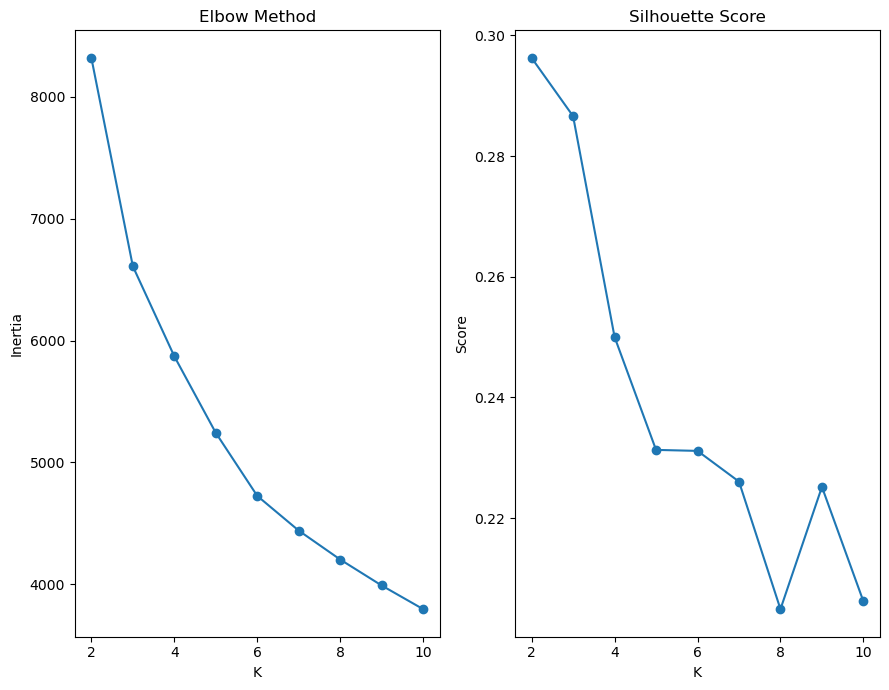

In [264]:
fig, ax = plt.subplots(1, 2, figsize=(9, 7))

ax[0].plot(K, inertia, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Inertia")

ax[1].plot(K, sil, marker="o")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("K")
ax[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

In [265]:
k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Silhouette:", round(silhouette_score(X_scaled, kmeans_labels), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, kmeans_labels), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_scaled, kmeans_labels), 3))
print(pd.Series(kmeans_labels).value_counts().sort_index())

Silhouette: 0.287
Davies-Bouldin: 1.353
Calinski-Harabasz: 876.975
0    793
1    721
2    533
Name: count, dtype: int64


In [266]:
results = {}
results["KMeans"] = {
    "n_clusters": 3,
    "Silhouette": round(silhouette_score(X_scaled, kmeans_labels), 3),
    "Davies-Bouldin": round(davies_bouldin_score(X_scaled, kmeans_labels), 3),
    "Calinski-Harabasz": round(calinski_harabasz_score(X_scaled, kmeans_labels), 1),
}

#### **2- DBSCAN**

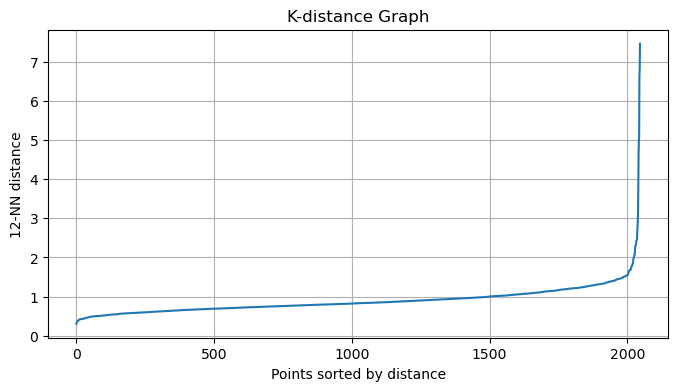

In [267]:
from sklearn.neighbors import NearestNeighbors

min_samples = 12 # 2*num of cols
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{min_samples}-NN distance")
plt.title("K-distance Graph")
plt.grid(True)
plt.show()

In [279]:
for eps in [0.9, 1.0, 1.05, 1.1]:
    for ms in [8, 10, 12]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        print(f"eps={eps}, min_samples={ms} --> clusters={n_clusters}, noise={n_noise} ({n_noise/len(labels)*100:.1f}%)")

eps=0.9, min_samples=8 --> clusters=4, noise=248 (12.1%)
eps=0.9, min_samples=10 --> clusters=4, noise=290 (14.2%)
eps=0.9, min_samples=12 --> clusters=4, noise=352 (17.2%)
eps=1.0, min_samples=8 --> clusters=5, noise=140 (6.8%)
eps=1.0, min_samples=10 --> clusters=4, noise=188 (9.2%)
eps=1.0, min_samples=12 --> clusters=4, noise=222 (10.8%)
eps=1.05, min_samples=8 --> clusters=5, noise=117 (5.7%)
eps=1.05, min_samples=10 --> clusters=5, noise=147 (7.2%)
eps=1.05, min_samples=12 --> clusters=4, noise=178 (8.7%)
eps=1.1, min_samples=8 --> clusters=5, noise=103 (5.0%)
eps=1.1, min_samples=10 --> clusters=5, noise=117 (5.7%)
eps=1.1, min_samples=12 --> clusters=4, noise=144 (7.0%)


In [274]:
db = DBSCAN(eps=1.1, min_samples=12).fit(X_scaled)
dbscan_labels = db.labels_
mask = dbscan_labels != -1

print("Silhouette:", round(silhouette_score(X_scaled[mask], dbscan_labels[mask]), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled[mask], dbscan_labels[mask]), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_scaled[mask], dbscan_labels[mask]), 1))
print(pd.Series(dbscan_labels).value_counts().sort_index())

Silhouette: 0.043
Davies-Bouldin: 2.468
Calinski-Harabasz: 257.4
-1    144
 0    796
 1    680
 2    183
 3    244
Name: count, dtype: int64


In [275]:
mask = dbscan_labels != -1
results["DBSCAN"] = {
    "n_clusters": 4,
    "Silhouette": round(silhouette_score(X_scaled[mask], dbscan_labels[mask]), 3),
    "Davies-Bouldin": round(davies_bouldin_score(X_scaled[mask], dbscan_labels[mask]), 3),
    "Calinski-Harabasz": round(calinski_harabasz_score(X_scaled[mask], dbscan_labels[mask]), 1),
}

#### **3- Agglomerative Clustering**

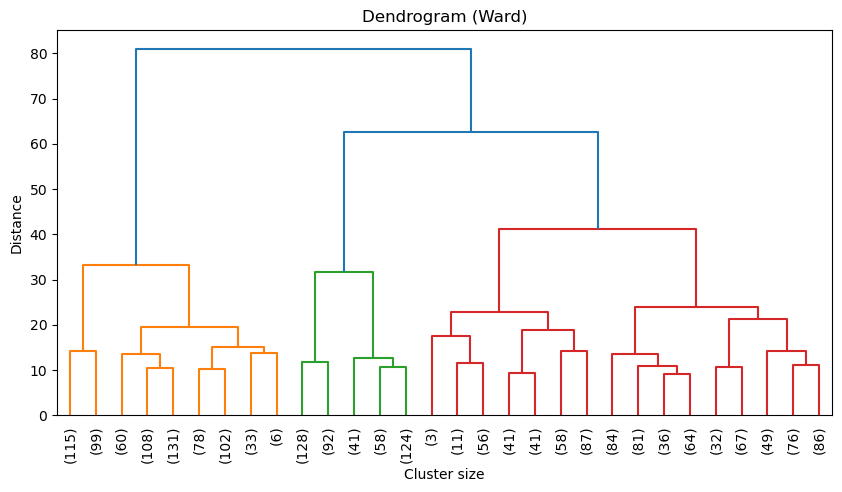

In [285]:
plt.figure(figsize=(10, 5))
Z = linkage(X_scaled, method="ward")
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogram (Ward)")
plt.xlabel("Cluster size")
plt.ylabel("Distance")
plt.show()

In [281]:
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
agg_labels = agg.fit_predict(X_scaled)

print("Silhouette:", round(silhouette_score(X_scaled, agg_labels), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, agg_labels), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_scaled, agg_labels), 1))
print(pd.Series(agg_labels).value_counts().sort_index())

Silhouette: 0.241
Davies-Bouldin: 1.446
Calinski-Harabasz: 760.1
0    872
1    732
2    443
Name: count, dtype: int64


In [282]:
results["Agglomerative"] = {
    "n_clusters": 3,
    "Silhouette": round(silhouette_score(X_scaled, agg_labels), 3),
    "Davies-Bouldin": round(davies_bouldin_score(X_scaled, agg_labels), 3),
    "Calinski-Harabasz": round(calinski_harabasz_score(X_scaled, agg_labels), 1),
}

#### **4- GMM**

In [289]:
bic, aic = [], []
K = range(2, 9)

for k in K:
    gmm = GaussianMixture(n_components=k, covariance_type="full", reg_covar=1e-2,
                          random_state=42, n_init=5).fit(X_scaled)
    bic.append(gmm.bic(X_scaled))
    aic.append(gmm.aic(X_scaled))

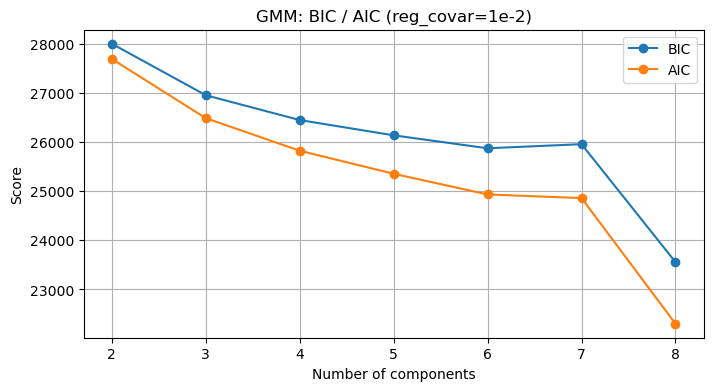

In [290]:
plt.figure(figsize=(8, 4))
plt.plot(K, bic, marker="o", label="BIC")
plt.plot(K, aic, marker="o", label="AIC")
plt.xlabel("Number of components")
plt.ylabel("Score")
plt.title("GMM: BIC / AIC (reg_covar=1e-2)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
rows = []
for cov in ["full", "tied", "diag", "spherical"]:
    for k in [3, 6]:
        gmm = GaussianMixture(n_components=k, covariance_type=cov, reg_covar=1e-2, random_state=42, n_init=5)
        labels = gmm.fit_predict(X_scaled)
        rows.append({
            "cov_type": cov,
            "K": k,
            "Silhouette": round(silhouette_score(X_scaled, labels), 3),
            "Davies-Bouldin": round(davies_bouldin_score(X_scaled, labels), 3),
            "Calinski-Harabasz": round(calinski_harabasz_score(X_scaled, labels), 1),
            "BIC": round(gmm.bic(X_scaled)),
            "Min_Size": np.bincount(labels).min(),
            "Sizes": np.bincount(labels).tolist(),
        })

gmm_compare = pd.DataFrame(rows)
display(gmm_compare)

,cov_type,K,Silhouette,Davies-Bouldin,Calinski-Harabasz,BIC,Min_Size,Sizes
0,full,3,0.255,1.518,765.8,26950,604,"[623, 820, 604]"
1,full,6,0.123,2.337,383.9,25870,21,"[200, 410, 21, 407, 425, 584]"
2,tied,3,0.289,1.224,692.4,28527,180,"[821, 180, 1046]"
3,tied,6,0.157,2.014,478.3,27646,23,"[194, 513, 23, 516, 303, 498]"
4,diag,3,0.253,1.458,800.2,28536,494,"[761, 792, 494]"
5,diag,6,0.152,2.780,470.4,27308,43,"[479, 428, 291, 389, 417, 43]"
6,spherical,3,0.284,1.429,847.0,31255,585,"[585, 762, 700]"
7,spherical,6,0.217,1.281,609.2,29311,158,"[665, 545, 224, 249, 158, 206]"


In [ ]:
# GMM: full covariance chosen for its flexibility (elliptical, correlated features).
# tied gave a higher silhouette (0.289) but produced a small cluster (180);
# spherical is nearly equivalent to KMeans, so it adds no new perspective.

In [292]:
gmm = GaussianMixture(n_components=3, covariance_type="full", reg_covar=1e-2, random_state=42, n_init=5)
gmm_labels = gmm.fit_predict(X_scaled)

results["GMM"] = {
    "n_clusters": 3,
    "Silhouette": round(silhouette_score(X_scaled, gmm_labels), 3),
    "Davies-Bouldin": round(davies_bouldin_score(X_scaled, gmm_labels), 3),
    "Calinski-Harabasz": round(calinski_harabasz_score(X_scaled, gmm_labels), 1),
}

#### **5- MeanShift**

In [294]:
rows = []
for q in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]:
    bw = estimate_bandwidth(X_scaled, quantile=q, random_state=42)
    labels = MeanShift(bandwidth=bw, bin_seeding=True).fit_predict(X_scaled)
    n = len(np.unique(labels))
    sizes = sorted(pd.Series(labels).value_counts(), reverse=True)
    sil = round(silhouette_score(X_scaled, labels), 3) if n > 1 else None
    rows.append({'quantile': q, 'bandwidth': round(bw, 2), 'n_clusters': n,
                 'sizes': sizes[:8], 'silhouette': sil})

ms_res = pd.DataFrame(rows)
display(ms_res)

,quantile,bandwidth,n_clusters,sizes,silhouette
0,0.10,1.83,10,"[1086, 932, 16, 4, 3, 2, 1, 1]",0.249
1,0.15,2.06,9,"[1979, 38, 13, 11, 2, 1, 1, 1]",0.046
2,0.20,2.25,9,"[1018, 1004, 16, 3, 2, 1, 1, 1]",0.279
3,0.25,2.44,7,"[2027, 11, 4, 2, 1, 1, 1]",0.375
4,0.30,2.61,7,"[2027, 11, 4, 2, 1, 1, 1]",0.375
5,0.40,2.93,5,"[2027, 11, 6, 2, 1]",0.418
6,0.50,3.24,3,"[2030, 14, 3]",0.457


In [295]:
bw = estimate_bandwidth(X_scaled, quantile=0.2, random_state=42)
ms = MeanShift(bandwidth=bw, bin_seeding=True)
ms_labels = ms.fit_predict(X_scaled)

sizes = pd.Series(ms_labels).value_counts()
big = sizes[sizes >= 100].index
mask = np.isin(ms_labels, big)

print("Big clusters:", len(big), "| Outliers:", (~mask).sum())
print("Silhouette:", round(silhouette_score(X_scaled[mask], ms_labels[mask]), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled[mask], ms_labels[mask]), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_scaled[mask], ms_labels[mask]), 1))

Big clusters: 2 | Outliers: 25
Silhouette: 0.301
Davies-Bouldin: 1.333
Calinski-Harabasz: 1021.8


In [ ]:
# Mean Shift: quantile=0.2 was chosen for the bandwidth because:
# - Higher quantiles (>= 0.25) merge almost all customers into one giant cluster (~2030),
#   and their high silhouette scores are misleading (driven by a few distant outliers).
# - quantile=0.1 and 0.2 are the only values that give a real split into two large clusters;
#   0.2 is slightly better (more balanced sizes: 1018 / 1004, fewer outliers: 25, higher silhouette).
# - Clusters smaller than 100 customers are treated as outliers and excluded from the metrics,
#   so Mean Shift effectively yields 2 real clusters, which makes its scores not directly
#   comparable to the 3-cluster models.

In [298]:
results["MeanShift"] = {
    "n_clusters": len(big),
    "Silhouette": round(silhouette_score(X_scaled[mask], ms_labels[mask]), 3),
    "Davies-Bouldin": round(davies_bouldin_score(X_scaled[mask], ms_labels[mask]), 3),
    "Calinski-Harabasz": round(calinski_harabasz_score(X_scaled[mask], ms_labels[mask]), 1),
}

### **=> Clustering Models Comparison**
---

In [301]:
results_df = pd.DataFrame(results).T
results_df["n_clusters"] = results_df["n_clusters"].astype(int)
display(results_df.sort_values("Silhouette", ascending=False))

,n_clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
MeanShift,2,0.301,1.333,1021.8
KMeans,3,0.287,1.353,877.0
GMM,3,0.255,1.518,765.8
Agglomerative,3,0.241,1.446,760.1
DBSCAN,4,0.043,2.468,257.4


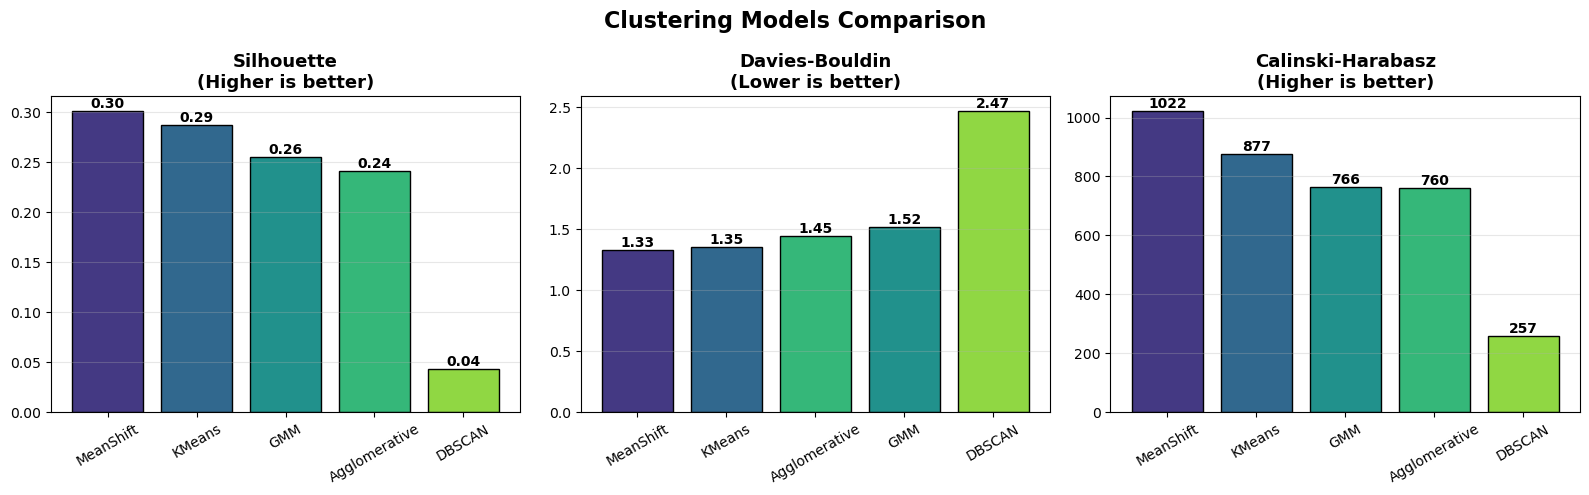

In [302]:
df_plot = results_df.sort_values("Silhouette", ascending=False)
color_map = dict(zip(df_plot.index, sns.color_palette("viridis", len(df_plot))))

metrics = [
    ("Silhouette", "Higher is better"),
    ("Davies-Bouldin", "Lower is better"),
    ("Calinski-Harabasz", "Higher is better"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (metric, note) in zip(axes, metrics):
    d = df_plot.sort_values(metric, ascending=(metric == "Davies-Bouldin"))
    bars = ax.bar(d.index, d[metric],
                  color=[color_map[m] for m in d.index], edgecolor="black")
    ax.set_title(f"{metric}\n({note})", fontsize=13, fontweight="bold")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
    for b in bars:
        label = f"{b.get_height():.0f}" if metric == "Calinski-Harabasz" else f"{b.get_height():.2f}"
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), label,
                ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.suptitle("Clustering Models Comparison", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### **=> Model Selection**
---

In [304]:
print("\nReason for Selection:")
print("- KMeans (K=3) has metrics very close to the best model (Mean Shift).")
print("- Mean Shift produced only 2 clusters and excluded 25 customers as outliers,")
print("  so its scores are not directly comparable to the 3-cluster models.")
print("- KMeans covers all customers with 3 balanced segments (793 / 721 / 533).")
print("- 3 segments are more useful for business profiling than 2.")
print("- KMeans is simple, fast, and easy to interpret.")


Reason for Selection:
- KMeans (K=3) has metrics very close to the best model (Mean Shift).
- Mean Shift produced only 2 clusters and excluded 25 customers as outliers,
  so its scores are not directly comparable to the 3-cluster models.
- KMeans covers all customers with 3 balanced segments (793 / 721 / 533).
- 3 segments are more useful for business profiling than 2.
- KMeans is simple, fast, and easy to interpret.


In [305]:
# Final model: K-Means (K=3)
final_model = kmeans
df["Cluster"] = kmeans_labels

print(df["Cluster"].value_counts().sort_index())

Cluster
0    793
1    721
2    533
Name: count, dtype: int64


### **=> PCA Visualization**
---

In [307]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance:", pca.explained_variance_ratio_.round(3))
print("Total:", round(pca.explained_variance_ratio_.sum(), 3))

Explained variance: [0.437 0.225]
Total: 0.663


e:\apps\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


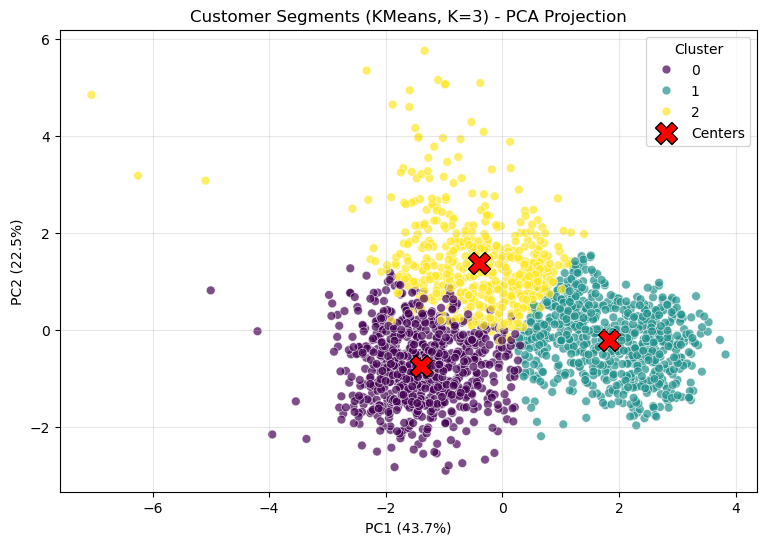

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["Cluster"],
                palette="viridis", alpha=0.7, s=40)

centers_pca = pca.transform(final_model.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="red", marker="X",
            s=250, edgecolor="black", label="Centers")

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Customer Segments (KMeans, K=3) - PCA Projection")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

### **=> Cluster Profiling**
---

In [311]:
profile = df.groupby("Cluster").agg({
    "Age": "mean",
    "Income": "mean",
    "Family_Size": "mean",
    "Total_Children": "mean",
    "Total_Spending": "mean",
    "Total_Purchases": "mean",
    "NumDealsPurchases": "mean",
    "NumWebVisitsMonth": "mean",
    "Total_Accepted_Cmp": "mean",
}).round(1)

profile["Size"] = df["Cluster"].value_counts().sort_index()
display(profile)

,Age,Income,Family_Size,Total_Children,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebVisitsMonth,Total_Accepted_Cmp,Size
Cluster,,,,,,,,,,
0,40.8,32341.9,2.8,1.2,82.8,5.5,1.8,6.6,0.1,793
1,46.9,72038.5,2.0,0.4,1169.6,18.4,1.3,3.1,0.6,721
2,49.1,52887.2,3.1,1.4,621.9,15.1,4.6,6.5,0.2,533


In [312]:
# Cluster profiles (KMeans, K=3):
# 0 - Budget Families: lowest income/spending, largest families, high web visits but few purchases.
# 1 - High-Value Customers: highest income/spending/purchases, smallest families, most campaign-responsive.
# 2 - Mid-Value Deal Seekers: mid income/spending, oldest, most children, highest use of discounts.

In [315]:
mnt_cols = ["MntWines", "MntFruits", "MntMeatProducts",
            "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
chan_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]

display(df.groupby("Cluster")[mnt_cols + chan_cols].mean().round(1))

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
Cluster,,,,,,,,,
0,31.1,5.0,19.7,7.3,4.8,14.9,2.0,0.4,3.0
1,548.8,54.6,360.8,79.3,57.0,69.0,5.2,5.0,8.2
2,382.9,19.6,119.7,25.7,20.5,53.4,5.8,2.7,6.7


In [316]:
display(pd.crosstab(df["Cluster"], df["Education"], normalize="index").round(2))
# Education profiling:
# - Graduate/Postgraduate are evenly split across all clusters, so education does not define a segment.
# - Undergraduates (very few customers) are almost entirely in Budget Families,
#   consistent with their lower spending.

Education,Graduate,Postgraduate,Undergraduate
Cluster,,,
0,0.49,0.45,0.06
1,0.53,0.47,0.00
2,0.49,0.51,0.01


In [ ]:
display(pd.crosstab(df["Cluster"], df["Marital_Status"], normalize="index").round(2))
# Marital status profiling:
# - Deal Seekers have the highest share of partnered customers (72%), matching their larger families.
# - High-Value Customers have the highest share of single/divorced customers (43%), matching the smallest families.
# - Divorced customers are spread evenly (9-12%), so marital status is a supporting detail, not a defining trait.

Marital_Status,Divorced,Partner,Single
Cluster,,,
0,0.09,0.64,0.27
1,0.12,0.58,0.31
2,0.11,0.72,0.17


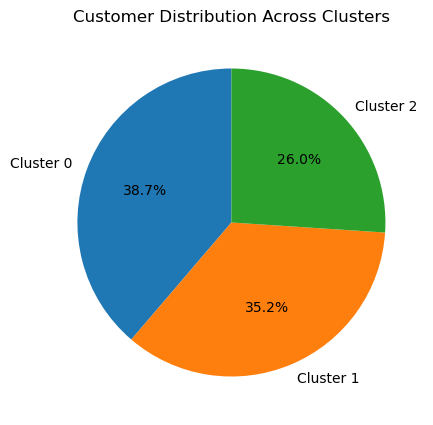

In [ ]:
cluster_counts = df["Cluster"].value_counts().sort_index()
plt.figure(figsize=(7,5))

plt.pie(
    cluster_counts,
    labels=[f"Cluster {i}" for i in cluster_counts.index],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Distribution Across Clusters")
plt.show()

C:\Users\e\AppData\Local\Temp\ipykernel_8016\1152954044.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


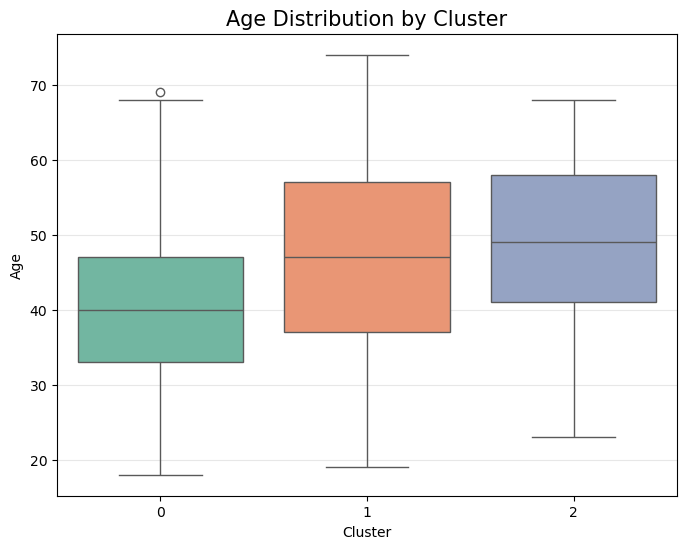

In [318]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=df,
    x="Cluster",
    y="Age",
    palette="Set2"
)

plt.title("Age Distribution by Cluster", fontsize=15)
plt.xlabel("Cluster")
plt.ylabel("Age")

plt.grid(axis="y", alpha=0.3)
plt.show()

C:\Users\e\AppData\Local\Temp\ipykernel_8016\315465345.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


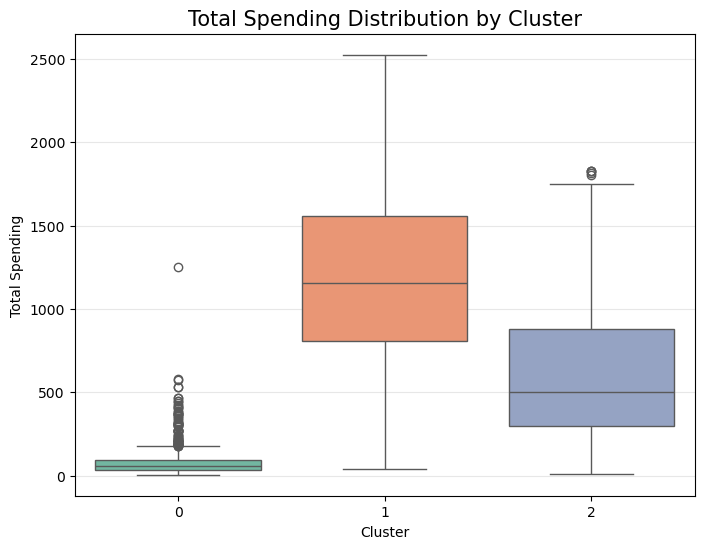

In [317]:
plt.figure(figsize=(8,6))
sns.boxplot(
    data = df,
    x="Cluster",
    y="Total_Spending",
    palette="Set2"
)

plt.title("Total Spending Distribution by Cluster", fontsize=15)
plt.xlabel("Cluster")
plt.ylabel("Total Spending")

plt.grid(axis="y", alpha=0.3)
plt.show()

### **=> Business Insights**
---

In [324]:
# ==========================================================
# Cluster Characteristics
# ==========================================================

summary = df.groupby("Cluster")[[
    "Age",
    "Income",
    "Total_Spending",
    "Total_Purchases",
    "Total_Accepted_Cmp",
    "MntMeatProducts",
    "MntWines"
]].mean().round(2)

print("=" * 70)
print("Cluster Characteristics")
print("=" * 70)

display(summary)

Cluster Characteristics


,Age,Income,Total_Spending,Total_Purchases,Total_Accepted_Cmp,MntMeatProducts,MntWines
Cluster,,,,,,,
0,40.83,32341.86,82.82,5.47,0.09,19.72,31.13
1,46.87,72038.48,1169.56,18.40,0.57,360.80,548.83
2,49.15,52887.20,621.91,15.13,0.25,119.73,382.91


In [ ]:
# Cluster profiles (KMeans, K=3):
# 0 - Budget Customers: lowest income, spending and purchases; youngest; almost never accepts campaigns.
# 1 - High-Value Customers: highest income, spending and purchases; most responsive to campaigns.
# 2 - Mid-Value Customers: mid income and spending; oldest; purchase frequency close to High-Value
#     despite roughly half the spending.

In [322]:
segment_names = {
    0: "Budget Customers",
    1: "High-Value Customers",
    2: "Mid-Value Customers",
}
df["Segment"] = df["Cluster"].map(segment_names)

In [323]:
recommendations = {
    "Budget Customers": [
        "Offer entry-level bundles and low-price essentials to raise basket size.",
        "Use discount coupons and limited-time promotions, since this group spends little per purchase.",
        "Encourage store visits and loyalty points to build purchase frequency.",
        "Avoid expensive premium campaigns: this segment rarely accepts them (0.09 on average).",
    ],
    "High-Value Customers": [
        "Launch a VIP / loyalty program with early access and exclusive offers.",
        "Promote premium wine and meat products, the main drivers of their spending.",
        "Use catalog and in-store channels, which this group uses most.",
        "Prioritize them for new campaigns: they are the most responsive (0.57 on average).",
        "Focus on retention, since losing even a few of these customers has a large revenue impact.",
    ],
    "Mid-Value Customers": [
        "Upsell with bundles and volume offers to raise spend per purchase, since their purchase frequency is close to High-Value.",
        "Promote online offers and web-exclusive deals, since this group buys online most often.",
        "Use targeted discounts to move them toward the High-Value segment.",
        "Run family-oriented promotions to match their larger households.",
    ],
}

for cluster_id, segment in segment_names.items():
    size = (df["Segment"] == segment).sum()
    print(f"\n{segment} (Cluster {cluster_id}, {size} customers)")
    for a in recommendations[segment]:
        print(f"  - {a}")


Budget Customers (Cluster 0, 793 customers)
  - Offer entry-level bundles and low-price essentials to raise basket size.
  - Use discount coupons and limited-time promotions, since this group spends little per purchase.
  - Encourage store visits and loyalty points to build purchase frequency.
  - Avoid expensive premium campaigns: this segment rarely accepts them (0.09 on average).

High-Value Customers (Cluster 1, 721 customers)
  - Launch a VIP / loyalty program with early access and exclusive offers.
  - Promote premium wine and meat products, the main drivers of their spending.
  - Use catalog and in-store channels, which this group uses most.
  - Prioritize them for new campaigns: they are the most responsive (0.57 on average).
  - Focus on retention, since losing even a few of these customers has a large revenue impact.

Mid-Value Customers (Cluster 2, 533 customers)
  - Upsell with bundles and volume offers to raise spend per purchase, since their purchase frequency is close t